<div style="padding: 20px 24px; border-radius: 12px; background: linear-gradient(110deg, #12304a, #187b8f); color: white; margin-bottom: 16px;">
  <div style="font-size: 0.78em; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.85;">HydroMT-SFINCS | Jakarta 04</div>
  <h1 style="color: white; margin: 8px 0 4px;">Validate the water levels against the SKLP tide gauge</h1>
  <div style="opacity: 0.95;">Read the SFINCS results and compare the water level with the BIG tide gauge at Sunda Kelapa, 28-30 Oct 2026.</div>
</div>


The model results are read as in the official example [5a_plot_results_hmax](https://deltares.github.io/hydromt_sfincs/latest/_examples/5a_plot_results_hmax.html). [JAKARTA] Instead of the maximum water depth we look at the water level time series at the observation points, because the goal is first an accurate water level at the coast.

### Steps

1. Read model results and inspect the model layout.
2. [JAKARTA] Read the SKLP tide gauge.
3. [JAKARTA] Plot the model against the tide gauge.
4. [JAKARTA] Error statistics and tidal components.

In [1]:
from os.path import join
import matplotlib.pyplot as plt

from hydromt_sfincs import SfincsModel

# [JAKARTA]
import glob
import numpy as np
import pandas as pd

MSL = 1.12  # [JAKARTA] m EGM2008
RAD0 = 1.72  # [JAKARTA] MSL pada skala sensor radar SKLP (datum BIG): muka air (m MSL) = RAD - 1.72
T0, T1 = "2026-10-28 00:00", "2026-10-30 09:00"  # [JAKARTA] rentang data sensor (UTC)

C:\Users\ASUS\miniconda3\envs\asemelehoy\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Step 1: Read model results

The map output uses staggered-grid conventions for regular grids and an unstructured mesh for quadtree grids. `mod.output.read()` handles these formats and makes the output variables available through `mod.output.data`.


In [2]:
sfincs_root = "../model/jakarta_2026_tanpa_struktur"  # [JAKARTA] (relative) path to sfincs root
mod = SfincsModel(sfincs_root, data_libs=["../data/data_catalog.yml"], mode="r")  # [JAKARTA] data catalog

In [3]:
# we can simply read the model results (sfincs_map.nc and sfincs_his.nc) using the output.read method
mod.output.read()

# the following variables have been found
list(mod.output.data.keys())

['inp',
 'mesh2d_face_x',
 'mesh2d_face_y',
 'zb',
 'msk',
 'zs',
 'zsmax',
 'total_runtime',
 'average_dt',
 'status',
 'point_zb',
 'point_zs']

Inspect the model layout. Boundary-cell plotting is disabled because it is not supported for quadtree grids.


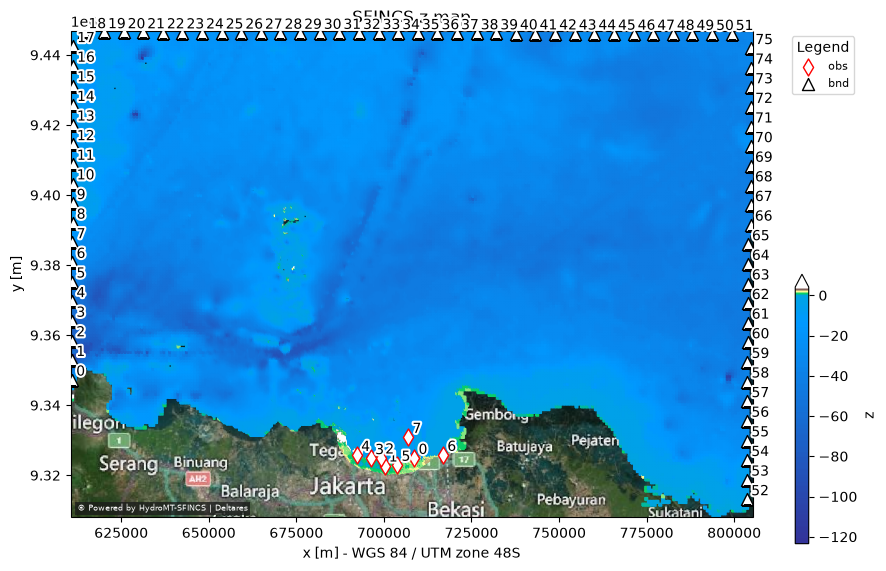

In [4]:
fig, ax = mod.plot_basemap(
    fn_out=None,
    bmap="sat",
    figsize=(11, 7),
    zoomlevel=9,  # [JAKARTA]
    plot_bounds=False,
)

### Step 2: [JAKARTA] Read the SKLP tide gauge

Raw 1-minute data of the two radars (RAD1, RAD2) of the BIG tide gauge SKLP Sunda Kelapa. Quality control: keep minutes where both radars agree within 5 cm, remove spikes more than 15 cm from the 3-hour running median, then average to 10 minutes. Water level in m MSL = RAD - 1.72 (BIG datum, see `../data/sensor/metadata_SKLP.txt`). All times are UTC.

In [5]:
df = pd.concat([pd.read_csv(f, sep="\t", skiprows=7, parse_dates=["timestamp"], index_col="timestamp")
                for f in sorted(glob.glob("../data/sensor/raw/sklp_*.txt"))])
df = df[~df.index.duplicated()].sort_index()
o = df[["RAD1", "RAD2"]].mean(axis=1)
o = o[(df.RAD1 - df.RAD2).abs() < 0.05]
o = o[(o - o.rolling("3h", center=True).median()).abs() < 0.15]
obs = (o - RAD0).resample("10min").mean().dropna()[T0:T1]
obs.describe()

count    341.000000
mean       0.094371
std        0.380675
min       -0.463500
25%       -0.279000
50%        0.116000
75%        0.473500
max        0.683571
dtype: float64

### Step 3: [JAKARTA] Model water level against the tide gauge

`point_zs` is the water level at the observation points (m EGM2008), converted to m MSL. Muara Angke is the main validation point. The SKLP cell lies in the narrow Sunda Kelapa basin, which the grid and DEM cannot resolve well: in the earlier 100 m model it damped the tide (range 0.90 m against 1.02 m in open water). Muara Baru, closer to the sensor, falls in a dry cell of this grid; in the earlier model Muara Baru and Muara Angke differed by only 1 mm at high tide.

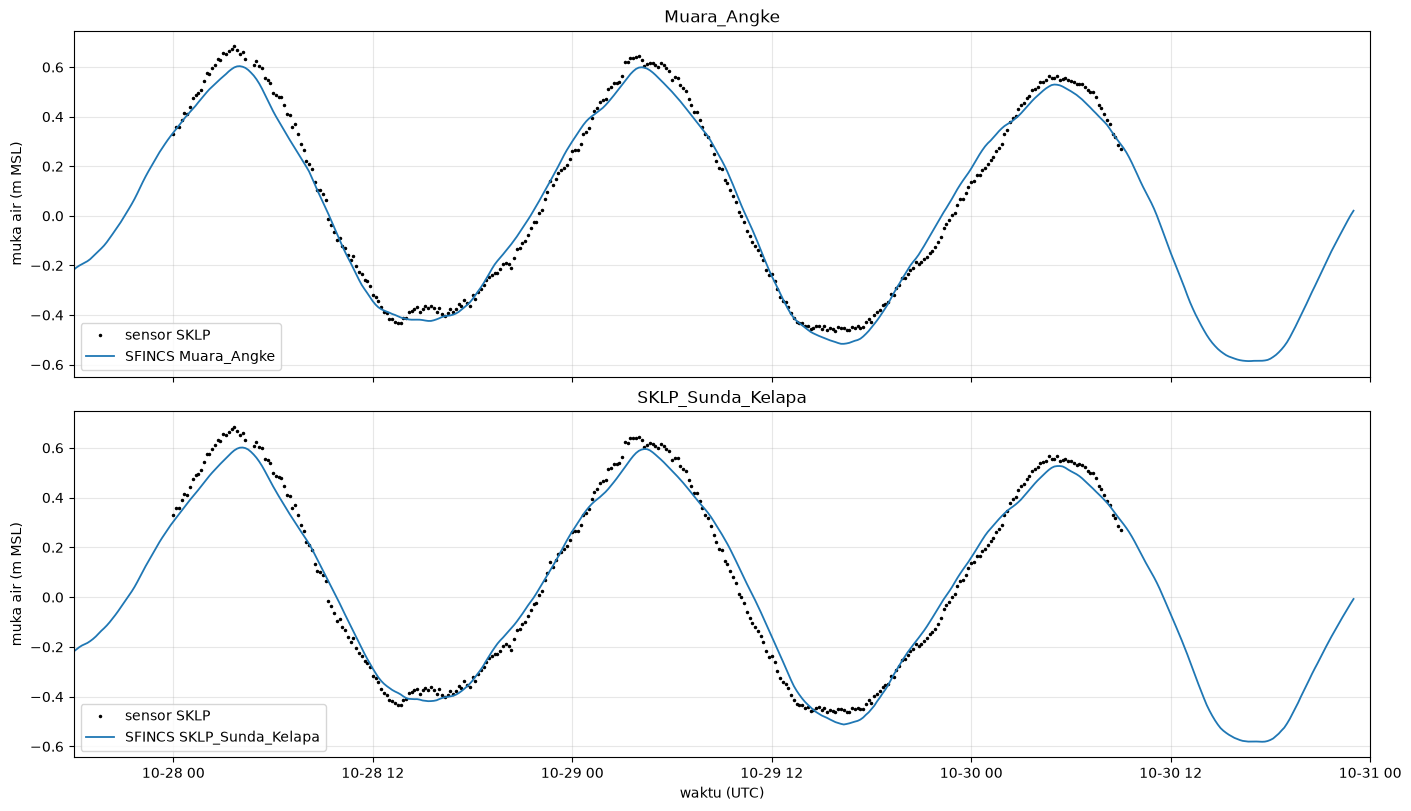

In [6]:
zs = mod.output.data["point_zs"].load()
nama = [s.decode().strip() if isinstance(s, bytes) else str(s).strip() for s in zs["station_name"].values]
titik = ["Muara_Angke", "SKLP_Sunda_Kelapa"]
model = {t: zs.isel(stations=nama.index(t)).to_series() - MSL for t in titik}

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, constrained_layout=True)
for ax, t in zip(axes, titik):
    ax.plot(obs.index, obs.values, ".", ms=3, color="k", label="sensor SKLP")
    ax.plot(model[t].index, model[t].values, lw=1.3, label=f"SFINCS {t}")
    ax.set_title(t); ax.set_ylabel("muka air (m MSL)"); ax.grid(alpha=0.3); ax.legend(loc="lower left")
axes[1].set_xlim(pd.Timestamp("2026-10-27 18:00"), pd.Timestamp("2026-10-31")); axes[1].set_xlabel("waktu (UTC)")
fig.savefig("../hasil/validasi_SKLP_tanpa_struktur.png", dpi=130)

### Step 4: [JAKARTA] Error statistics and tidal components

- **bias, RMSE, r**: on the 10-minute values of 28 Oct 00:00 to 30 Oct 09:00 UTC.
- **puncak_28/29/30**: highest model level minus highest sensor level of that day (cm). This is the main metric: the model must not underestimate high tide.
- **D1, D2**: amplitude (cm) of the diurnal (24.84 h) and semi-diurnal (12.42 h) tide, from a least-squares fit of mean + D1 + D2 + D4 (6.21 h). The record is only 2.4 days, so these are bands of constituents (K1+O1+P1, M2+S2), not single constituents.
- **rentang**: highest minus lowest level in the record (m).

In [7]:
def harmonik(s):
    t = (s.index - pd.Timestamp(T0)).total_seconds().values / 3600
    A = [np.ones_like(t)]
    for p in [24.84, 12.42, 6.21]:
        w = 2 * np.pi / p
        A += [np.cos(w * t), np.sin(w * t)]
    c = np.linalg.lstsq(np.array(A).T, s.values, rcond=None)[0]
    return 100 * c[0], 100 * np.hypot(c[1], c[2]), 100 * np.hypot(c[3], c[4])


hari = ["2026-10-28", "2026-10-29", "2026-10-30"]
m0, d1, d2 = harmonik(obs)
baris = [dict(titik="sensor SKLP", mean=m0, D1=d1, D2=d2, rentang=obs.max() - obs.min())]
for t in titik:
    m = model[t]
    j = pd.concat([obs.rename("o"), m.rename("m")], axis=1).dropna()
    e = 100 * (j.m - j.o)
    pk = [100 * (m[d].max() - obs[d].max()) for d in hari]
    m0, d1, d2 = harmonik(j.m)
    baris.append(dict(titik=t, bias=e.mean(), rmse=np.sqrt((e ** 2).mean()), r=np.corrcoef(j.m, j.o)[0, 1],
                      puncak_28=pk[0], puncak_29=pk[1], puncak_30=pk[2], puncak_rata2=np.mean(pk),
                      mean=m0, D1=d1, D2=d2, rentang=j.m.max() - j.m.min()))
tabel = pd.DataFrame(baris).set_index("titik").round(2)
tabel.to_csv("../hasil/statistik_validasi_tanpa_struktur.csv")
tabel

C:\Users\ASUS\AppData\Local\Temp\ipykernel_8208\883900596.py:16: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  j = pd.concat([obs.rename("o"), m.rename("m")], axis=1).dropna()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_8208\883900596.py:16: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  j = pd.concat([obs.rename("o"), m.rename("m")], axis=1).dropna()


,mean,D1,D2,rentang,bias,rmse,r,puncak_28,puncak_29,puncak_30,puncak_rata2
titik,,,,,,,,,,,
sensor SKLP,3.58,51.62,7.00,1.15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Muara_Angke,2.97,50.74,3.76,1.12,-1.03,4.78,0.99,-7.97,-4.62,-3.64,-5.41
SKLP_Sunda_Kelapa,3.74,49.37,3.56,1.11,-0.42,5.17,0.99,-8.21,-5.01,-3.91,-5.71
